<img src="https://ga-curriculum.github.io/universal-resources-internal/ga-logos/ga-red-cog-72x72.png" alt="" style="float: left; margin: 20px 20px 0 0; height: 55px">

# List Comprehensions and More

_Author: Tim Book_

---

### Learning Objectives
By the end of this lesson, students should be able to: 
- Be able to map and filter lists using list comprehensions
- Create more compact loops/listcomps using the `zip` and `enumerate` functions
* More exotic types of loops such as:
    * Looping across dictionaries and lists of tuples
    * Dict comprehensions
- If time:
    - Know the basics of lambda functions, and when one might use them
    - Understand the truthiness nature of booleans, and use them creatively with `None` and the ternary operator to create more compact if-statements
    - Understand how lists actually share computer memory and avoid those complications

# List Comprehensions
_"Listcomps" for short_

You may have noticed that, very often, we want to perform actions that boil down to:

> _Take a list and do something to every element of that list, making a new list._

This is so common that Python has a special super-efficient shortcut for this: **list comprehensions**. They have the following form:

```python
[do_thing(i) for i in my_list]
```

For example, **if we wanted to double every element of a list**, we used to do this:

In [1]:
my_list = [1, 4, 5, 2, 10]
double_list = []
for item in my_list:
    double_list.append(2*item)
print(double_list)

[2, 8, 10, 4, 20]


Now, we can write:

In [2]:
my_list = [1, 4, 5, 2, 10]
double_list = [2*item for item in my_list]
print(double_list)

[2, 8, 10, 4, 20]


## Listcomps for "mapping"
Just like we did in the previous cell, listcomps are most often used for transforming entire lists of data into something else. Let's do several exercises.

#### Exercise 1
What is the sum of the squares of the first 100 integers? That is, what is:

$$1^2 + 2^2 + 3^2 + \cdots + 100^2$$

_Hint:_ You can use the `sum()` function.

In [3]:
sum([n**2 for n in range(1, 101)])

338350

#### Exercse 2
Given the list of survey responses, reduce this list to the capital(!) first letter of each so we can get uniform results.

In [4]:
results = ['yes', 'no', 'Yeah', 'nope', 'Nah', 'YES!!!', 'Ya', 'No way!', 'no thank you']

In [5]:
[res[0].upper() for res in results]

['Y', 'N', 'Y', 'N', 'N', 'Y', 'Y', 'N', 'N']

#### Exercise 3
Given the list of names, create a list of only their last names

In [6]:
names = ['Tim Book', 'Ed Salinas', 'Hunter Wallen', 'Paul Stromberg', 'Steph Laraway']

In [7]:
[name.split()[1] for name in names]

['Book', 'Salinas', 'Wallen', 'Stromberg', 'Laraway']

#### Exercise 4
The prices below are in USD. This online retailer has decided to begin accepting Dogecoin, the world's foremost cryptocurrency. At the time of this writing, 1 Doge = 0.12 USD. Create a list of these prices converged to Dogecoin **rounded to the nearest Doge.**

In [8]:
prices = [3.99, 123.50, 32.00, 20.99, 87.20, 17.25, 50.00]

In [9]:
prices_doge = [round(pr/0.12) for pr in prices]
prices_doge

[33, 1029, 267, 175, 727, 144, 417]

## Listcomps for "filtering"
In addition to transforming entire lists, we also like to remove items from this list that don't meet some criteria. Listcomps give us a very easy way to do this, too:

```python
[do_thing(i) for i in my_list if some_condition(i)]
```

#### Exercise 5
Filter this list down to only even numbers.

In [10]:
numbers = [1, 4, 7, 2, 8, 11, 20]
evens_only = [i for i in numbers if i % 2 == 0]
evens_only

[4, 2, 8, 20]

#### Exercise 6
Select only the months that end in y.

In [11]:
months = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

In [12]:
[month for month in months if month[-1] == 'y']

['January', 'February', 'May', 'July']

#### Exercise 7
Select only the months that **don't** end in y. Also, only show their 3-letter abbreviations (the first 3 letters of the month name).

That is, the first 3 elements of your answer should be: `Mar`, `Apr`, `Jun`.

In [13]:
[month[:3] for month in months if month[-1] != 'y']

['Mar', 'Apr', 'Jun', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

#### Exercise 8
**Part A:** Write a function `get_initials()` that takes a name and returns its intials in the following way:

`get_initials("Tim Book") --> "T.B."`

You may assume the input will always be single-word names.

In [14]:
def get_initials(name):
    fname, lname = name.split()
    f_init = fname[0].upper()
    l_init = lname[0].upper()
    return f"{f_init}.{l_init}."

In [15]:
get_initials("Tim Book")

'T.B.'

**Part B:**
Take the list of names from exercise 3 and create a list of their initials.

In [16]:
[get_initials(name) for name in names]

['T.B.', 'E.S.', 'H.W.', 'P.S.', 'S.L.']

## Breakout Room: Roster Cleanup
Below we have a list of student who have signed up for a course. However, there are two problems:

* Since the fields were entered manually, names are not capitalized correctly.
* Some spam bots have joined our course!

Please correct this class roster to fix the capitalization and to remove all the bots. You can tell a student is a bot if their name discreetly contains the word "Robot".

For example:

* `tim boOk` -> `Tim Book`
* `Robot Jones` -> _[deleted]_

**Hints:**
* The word "robot" can be detected easily if everything is lowercase with all spaces removed.
* A good way to do this problem would be to write a function that is used to detect the word "robot", and put it in your final listcomp. This would clean up your code immensely.

In [17]:
students_raw = [
    'tim boOk',
    'robot Downey jr.',
    'Xiaofei zhou',
    'justin Strait',
    'louis robotnowitz',
    'matt brems',
    'Heathro Botkowski',
    'corey smith',
    'qian qian',
    'tyler o bottoms'
]

In [18]:
def detect_robot(name):
    return 'robot' in name.replace(' ', '').lower()

In [19]:
students = [student.title() for student in students_raw if not detect_robot(student)]
students

['Tim Book',
 'Xiaofei Zhou',
 'Justin Strait',
 'Matt Brems',
 'Corey Smith',
 'Qian Qian']

## Zips and Enumerates
Python contains two iterator helper functions: `zip()` and `enumerate()` to help us shorten some pretty common loop patterns.

In [20]:
letters = ['A', 'B', 'C']
fruits = ['Apple', 'Banana', 'Cherry']

#### Enumerate: Looping and Counting at the same time

In [21]:
for i, letter in enumerate(letters):
    print(f"{letter} is is letter number {i + 1}")

A is is letter number 1
B is is letter number 2
C is is letter number 3


In [22]:
[f"{letter} is letter number {i + 1}" for i, letter in enumerate(letters)]

['A is letter number 1', 'B is letter number 2', 'C is letter number 3']

#### Zip: Joining lists together in a loop

In [23]:
for letter, fruit in zip(letters, fruits):
    print(f"{letter} is for {fruit}")

A is for Apple
B is for Banana
C is for Cherry


In [24]:
[f"{letter} is for {fruit}" for letter, fruit in zip(letters, fruits)]

['A is for Apple', 'B is for Banana', 'C is for Cherry']

# Exotic Loops

### Loop 1: List of tuples
More often than you think, data are given to you as a list of tuples. You can "unpack" these tuples right in the `for` clause of the loop!

In [1]:
scores = [
    ('Tim', 100),
    ('Katie', 99),
    ('Chloe', 32),
    ('Matt', 77),
    ('Noelle', 88),
    ('Riley', 63)
]

In [2]:
for name, score in scores:
    print(f"{name} got a {score} on the test!")

Tim got a 100 on the test!
Katie got a 99 on the test!
Chloe got a 32 on the test!
Matt got a 77 on the test!
Noelle got a 88 on the test!
Riley got a 63 on the test!


### Loop 2: Dictionaries
You'll often want to loop through dictionaries, too! This is made easy with the `.items()` method.

**BIG NOTE:** Remember that dictionaries are "orderless," meaning you're supposed to treat them as the order does not matter. Modern versions of Python _do_ guarantee an internal order to dictionaries, but older ones don't. Using dictionaries in a way that assumes dictionaries are ordered is considered to be _bad practice!_

In [3]:
scores = {
    'Tim': 100,
    'Katie': 99,
    'Chloe': 32,
    'Matt': 77,
    'Noelle': 88,
    'Riley': 63
}

In [4]:
for name, score in scores.items():
    print(f"{name} got a {score} on the test!")

Tim got a 100 on the test!
Katie got a 99 on the test!
Chloe got a 32 on the test!
Matt got a 77 on the test!
Noelle got a 88 on the test!
Riley got a 63 on the test!


### Loop 3: Dict comprehensions
Using similar syntax to listcomps, you can even create a dictionary comprehension!

In [9]:
from random import randint

names = ['Tim', 'Katie', 'Chloe', 'Matt', 'Noelle', 'Riley']

# Fun fact: this is also how Katie and I assign final grades.
random_scores = {name: randint(1, 100) for name in names}

In [8]:
random_scores

{'Tim': 81, 'Katie': 40, 'Chloe': 5, 'Matt': 66, 'Noelle': 63, 'Riley': 24}

### Side Note: This is also the easiest way to "invert" a dictionary

In [10]:
first_as_keys = {
    'Tim': 'Book',
    'Katie': 'Sylvia',
    'Erica': 'Hennessy',
    'Simanto': 'Khandaker',
    'Brittany': 'Lewis'
}

In [11]:
last_as_keys = {v: k for k, v in first_as_keys.items()}
last_as_keys

{'Book': 'Tim',
 'Sylvia': 'Katie',
 'Hennessy': 'Erica',
 'Khandaker': 'Simanto',
 'Lewis': 'Brittany'}

---

# BELOW THIS LINE: BONUS MATERIAL!

_Note that "bonus" does not mean "unnecessary". It means "there probably won't be time, but this is still pretty crucial knowledge for any Python programmer." We'll get to it all eventually._

# Lambda Functions: Why name disposable functions?
So far we've separated the concept of a "function" from that of a "variable". But really, functions _are_ variables, and can be used as such. Functions can take other functions are arguments and even return functions. Functions that do this are called **higher order functions**, and they hurt your brain to think about. Enter Alonzo Church:

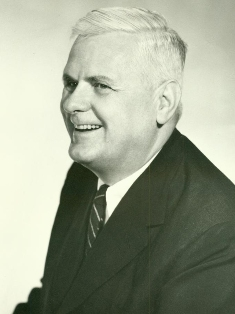

**Lambda functions** are "anonymous functions" - single-use functions that never get a name. The lambda function that doubles its input would look like this:

```python
lambda x: 2*x
```

We'll explore these more when we get to doing data science, but for now, two mindbending examples:

#### Functions as Function Input

In [25]:
def do_thing(f, x):
    return f(x)

In [26]:
def double(x):
    return 2*x

do_thing(double, 3)

6

In [27]:
do_thing(lambda x: 2*x, 3)

6

#### Functions as Function Output
_(We're creating what's called a "function factory")_

In [28]:
def adder(x):
    return lambda y: x + y

In [29]:
add1 = adder(1)
add3 = adder(3)

In [30]:
add1(2)

3

In [31]:
add3(5)

8

## Some Fun Function Vocab
The above examples can be very confusing the first time you try to understand what's happening. There's an entire subset of computer programmers who _love_ this stuff. This style is programming is called **functional programming** and I am one such person who loves this stuff. Luckily for you, Python is more of an **object-oriented programming language** rather than a functional one.

Even still, we need to know some concept of FP, especially when we get to working with data. Two more concepts:

* **maps** are functions that you apply to lists to do a calculation on each element of a list.
* **filters** are function that you apply to a list to remove unwanted elements.

The most convenient way to map and filter in Python is with listcomps:

```python
[map(item) for item in my_list if filter(item)]
```

But the traditional map and filters also exist in python:

In [32]:
numbers = [2, 8, 4, 6, 10, 1]

In [33]:
list(map(lambda x: x + 1, numbers))

[3, 9, 5, 7, 11, 2]

In [34]:
list(filter(lambda x: x > 5, numbers))

[8, 6, 10]

# The NoneType "None"
Python has a very special value `None` which is used to represent a null value. Its type is `NoneType`. That's it. It's just nothing.

In [35]:
None

In [36]:
type(None)

NoneType

In [37]:
None is None

True

... by the way, what happens if you don't have a `return` in a function?

In [38]:
def f1():
    return "Hello"

def f2():
    print("Hello")

In [39]:
f1()

'Hello'

In [40]:
f2()

Hello


In [41]:
s1 = f1()
s2 = f2()

Hello


In [42]:
s1

'Hello'

In [43]:
s2

In [44]:
type(s2)

NoneType

# The Ternary Operator
The "this or that" logic of if-statements can be shortened to one line in Python. For example:

In [45]:
x = 3
parity = "EVEN" if x % 2 == 0 else "ODD"
print(x)

3


That's pretty much it! Don't be confused by the keywords `if` and `else` - even though they're familiar to us, they're being used in a completely new type of statement here.

# Truthiness
![](imgs/truthiness.png)

Everything in Python has a "truthiness" to it - that is, whether or not it's `True` or `False` if you're pressured to pick.

In [46]:
bool(3)

True

In [47]:
bool(0)

False

In [48]:
bool(-1)

True

In [49]:
bool("Hello")

True

In [50]:
bool("False")

True

In [51]:
bool('')

False

In [52]:
bool([False])

True

In [53]:
bool([])

False

In [54]:
bool(None)

False

In [55]:
def make_ice_cream(flavor, n_scoops, toppings=None):
    print(f"Preparing {flavor} ice cream...")
    print(f"Scooping up {n_scoops} scoops...")
    if toppings:
        for topping in toppings:
            print(f"Adding {topping}...")
    print("Ice cream complete.")

In [56]:
make_ice_cream("chocolate", 3)

Preparing chocolate ice cream...
Scooping up 3 scoops...
Ice cream complete.


In [57]:
make_ice_cream("banana", 3, toppings=["peanut butter", "oreo crumbles"])

Preparing banana ice cream...
Scooping up 3 scoops...
Adding peanut butter...
Adding oreo crumbles...
Ice cream complete.


# List Copying
Be careful!!! Lists aren't as simple as they seem.

In [58]:
a = [1, 2, 3, 4, 5]
b = a
a[2] = 99
b[3] = 101
print(a)
print(b)

[1, 2, 99, 101, 5]
[1, 2, 99, 101, 5]


In [59]:
def add_value(my_list, item):
    my_list.append(item)
    return(my_list)

In [60]:
c = [1, 2, 3]
c_out = add_value(c, 4)

In [61]:
c

[1, 2, 3, 4]

In [62]:
c_out

[1, 2, 3, 4]

In [63]:
def add_value_fixed(my_list, item):
    new_list = my_list.copy()
    new_list.append(item)
    return(new_list)

In [64]:
d = [1, 2, 3]
d_out = add_value_fixed(d, 4)

In [65]:
d

[1, 2, 3]

In [66]:
d_out

[1, 2, 3, 4]

# Finally: Enter the Python Proving Grounds
Most of what we've seen so far aren't useful programs by themselves. You might even just call them "coding puzzles". Believe it or not, you're developing real skills that _will_ help you solve real problems. In the meantime, if you like this kind of thing, you're ready for some online coding challenge websites!

* [Codewars](https://codewars.com)
* [Project Euler](https://projecteuler.net/about)
* [FiveThirtyEight's "The Riddler" column](https://fivethirtyeight.com/tag/the-riddler/)
* [Advent of Code](https://adventofcode.com/)